In [1]:
import re
import pandas as pd

df = pd.read_csv("../dataset/expenses.csv")
df.head()

,description,category
0,PAYTM*HOTSTAR Pvt Ltd,Entertainment
1,NEFT-Myntra Delhi #39970,Shopping
2,Air India #91018,Travel
3,GPay RedBus India 2735,Travel
4,UPI-PETROL India #21079,Transport


In [2]:
NOISE_WORDS = {"upi", "dr", "pos", "paytm", "phonepe", "gpay", "neft", "imps", "ref", "txn"}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"@\w+", " ", text)       # bank handles like @ybl
    text = re.sub(r"[^a-z\s]", " ", text)   # numbers and symbols
    words = [w for w in text.split() if w not in NOISE_WORDS]
    return " ".join(words)

df["clean"] = df["description"].apply(clean_text)
df[["description", "clean"]].head(10)

,description,clean
0,PAYTM*HOTSTAR Pvt Ltd,hotstar pvt ltd
1,NEFT-Myntra Delhi #39970,myntra delhi
2,Air India #91018,air india
3,GPay RedBus India 2735,redbus india
4,UPI-PETROL India #21079,petrol india
5,PhonePe Meesho 9791,meesho
6,PhonePe Lab test Delhi Ref 146465890,lab test delhi
7,UPI/MUSIC SUBSCRIPTION Order 74317795@ybl,music subscription order
8,GPay Starbucks Bangalore Ref 366436049,starbucks bangalore
9,IMPS-Mobile accessories Pvt Ltd #31107,mobile accessories pvt ltd


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["category"],
    test_size=0.2, random_state=42, stratify=df["category"]
)
print(len(X_train), "train rows,", len(X_test), "test rows")

2200 train rows, 550 test rows


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))),
    ("clf", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)
print("Trained!")

Trained!


In [5]:
print("Test accuracy:", round(model.score(X_test, y_test), 4))

Test accuracy: 1.0


In [6]:
samples = ["Swiggy order 450", "Uber ride Jaipur", "Netflix subscription",
           "Monthly rent March", "Apollo pharmacy", "Some random shop"]
print(list(zip(samples, model.predict([clean_text(s) for s in samples]))))

[('Swiggy order 450', 'Food'), ('Uber ride Jaipur', 'Transport'), ('Netflix subscription', 'Entertainment'), ('Monthly rent March', 'Rent'), ('Apollo pharmacy', 'Health'), ('Some random shop', 'Food')]


In [7]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

                   precision    recall  f1-score   support

Bills & Utilities       1.00      1.00      1.00        50
    Entertainment       1.00      1.00      1.00        50
             Food       1.00      1.00      1.00        50
        Groceries       1.00      1.00      1.00        50
           Health       1.00      1.00      1.00        50
            Other       1.00      1.00      1.00        50
    Personal Care       1.00      1.00      1.00        50
             Rent       1.00      1.00      1.00        50
         Shopping       1.00      1.00      1.00        50
        Transport       1.00      1.00      1.00        50
           Travel       1.00      1.00      1.00        50

         accuracy                           1.00       550
        macro avg       1.00      1.00      1.00       550
     weighted avg       1.00      1.00      1.00       550



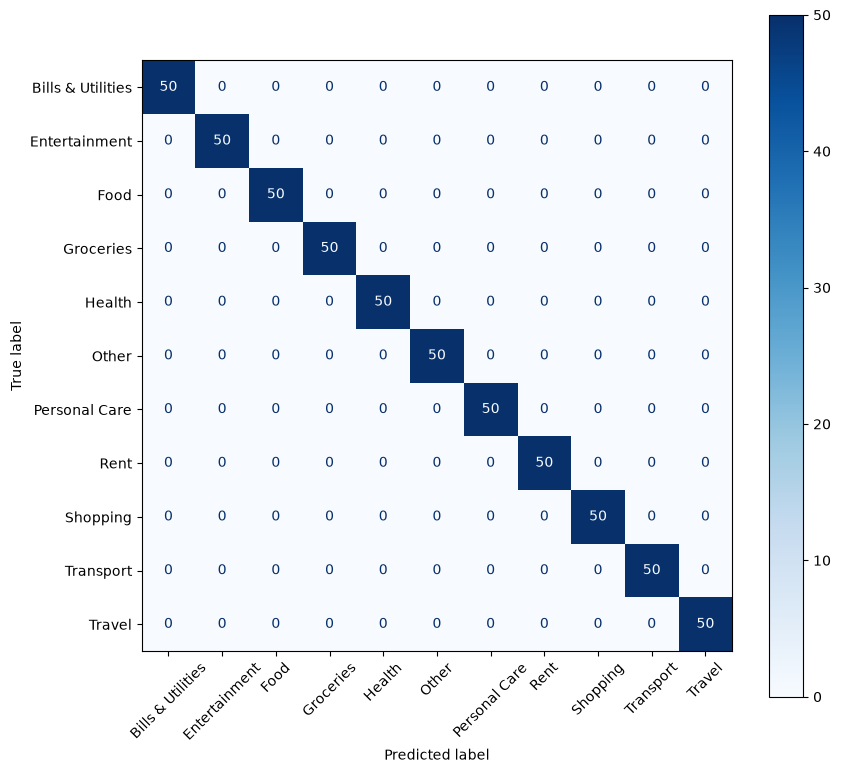

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=45, cmap="Blues", ax=ax
)
plt.tight_layout()
plt.show()

In [9]:
errors = pd.DataFrame({
    "description": df.loc[X_test.index, "description"],
    "actual": y_test,
    "predicted": y_pred,
})
errors = errors[errors["actual"] != errors["predicted"]]
print(len(errors), "mistakes out of", len(y_test))
errors.head(15)

0 mistakes out of 550


,description,actual,predicted


In [10]:
tests = [
    "Chai Sutta Bar", "Dominos pizza", "Ola ride to airport", "Zepto groceries",
    "Doctor consultation fee", "Electricity bill", "IRCTC ticket booking",
    "Amazon order", "Paid to Rahul", "Salon haircut", "Monthly SIP",
]
probs = model.predict_proba([clean_text(t) for t in tests])
for t, p in zip(tests, probs):
    best = model.classes_[p.argmax()]
    print(f"{t:30s} -> {best:20s} (confidence {p.max():.0%})")

Chai Sutta Bar                 -> Food                 (confidence 75%)
Dominos pizza                  -> Food                 (confidence 87%)
Ola ride to airport            -> Transport            (confidence 88%)
Zepto groceries                -> Groceries            (confidence 93%)
Doctor consultation fee        -> Health               (confidence 76%)
Electricity bill               -> Bills & Utilities    (confidence 96%)
IRCTC ticket booking           -> Travel               (confidence 97%)
Amazon order                   -> Shopping             (confidence 78%)
Paid to Rahul                  -> Other                (confidence 76%)
Salon haircut                  -> Personal Care        (confidence 98%)
Monthly SIP                    -> Other                (confidence 77%)
